# P6 – Scoring crédit « Prêt à dépenser »
## Notebook 01 : préparation des données

**Objectif** : transformer les 8 tables Home Credit en **une seule table client**
(une ligne par `SK_ID_CURR`), prête pour la modélisation.

**Méthode** : adaptation du kernel Kaggle *LightGBM with Simple Features* (J. Aguiar),
réécrit pour tenir en 8 Go de RAM. Le code est dans `preprocessing.py` ; ce notebook
l'appelle étape par étape.

| Choix technique | Pourquoi |
|---|---|
| `float32` / `uint8` | divise la mémoire par 2 à 8 |
| `bureau_balance` lu par blocs | 27 M de lignes : ne tient pas en une fois |
| parquet au lieu de CSV | conserve les types, 10× plus rapide |
| une étape = un fichier | si le noyau plante, on reprend là où on s'est arrêté |

**Sorties** (dans `processed/`) : `features_train.parquet`, `features_test.parquet`.

In [3]:
import gc
import logging
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import preprocessing as pp

logging.basicConfig(
    level=logging.INFO, format="%(asctime)s | %(message)s", datefmt="%H:%M:%S", force=True
)

# Dossier des CSV Home Credit (modifiable avec la variable d'environnement P6_DATA_DIR)
RAW_DIR = Path(
    os.environ.get(
        "P6_DATA_DIR",
        r"D:\Python_Datascience\Projet_OC6\Projet+Mise+en+prod+-+home-credit-default-risk",
    )
)
PROCESSED_DIR = RAW_DIR / "processed"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
print("Données :", RAW_DIR)

Données : D:\Python_Datascience\Projet_OC6\Projet+Mise+en+prod+-+home-credit-default-risk


In [4]:
EXPECTED = [
    "application_train.csv", "application_test.csv", "bureau.csv", "bureau_balance.csv",
    "previous_application.csv", "POS_CASH_balance.csv", "installments_payments.csv",
    "credit_card_balance.csv",
]
missing = [name for name in EXPECTED if not (RAW_DIR / name).exists()]
assert not missing, f"Fichiers manquants dans {RAW_DIR} : {missing}"
print("Les 8 fichiers sont présents.")

Les 8 fichiers sont présents.


### 1. Coup d'œil à la table principale

On regarde uniquement `application_train` (une ligne = une demande de crédit)
pour comprendre la cible et la qualité des données.

Dimensions : (307511, 122)
Mémoire    : 563 Mo


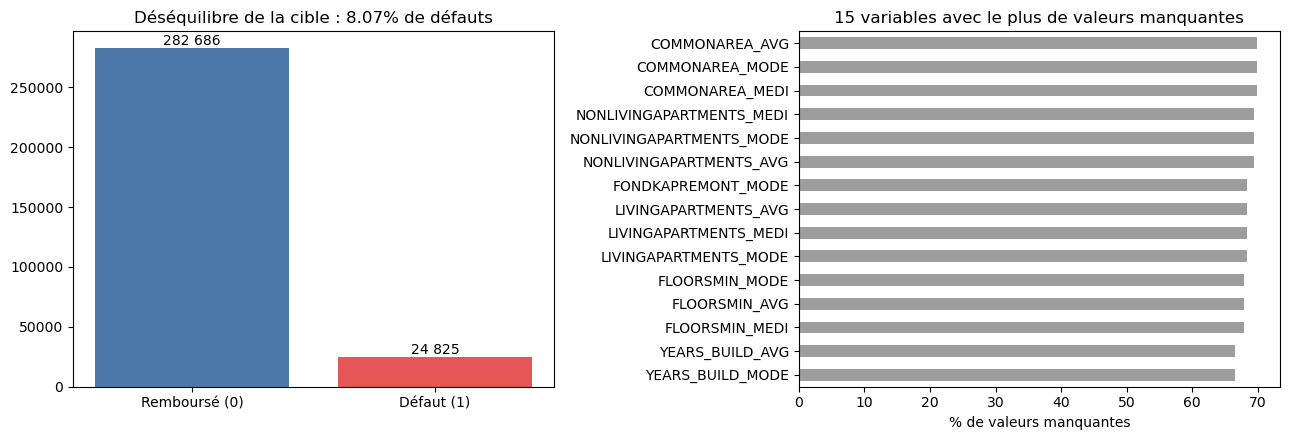

In [5]:
train = pd.read_csv(RAW_DIR / "application_train.csv")
print("Dimensions :", train.shape)
print(f"Mémoire    : {train.memory_usage(deep=True).sum() / 1e6:.0f} Mo")

rate = train["TARGET"].mean()
counts = train["TARGET"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(["Remboursé (0)", "Défaut (1)"], counts.values, color=["#4C78A8", "#E45756"])
axes[0].set_title(f"Déséquilibre de la cible : {rate:.2%} de défauts")
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}".replace(",", " "), ha="center", va="bottom")

missing_rate = train.isna().mean().sort_values(ascending=False).head(15) * 100
missing_rate[::-1].plot.barh(ax=axes[1], color="#9D9D9D")
axes[1].set_title("15 variables avec le plus de valeurs manquantes")
axes[1].set_xlabel("% de valeurs manquantes")
plt.tight_layout()
plt.savefig(FIG_DIR / "P6_01_cible_et_manquants.png", dpi=150)
plt.show()

In [6]:
del train
gc.collect()

393

**À retenir**
- La cible est **déséquilibrée** (~8 % de défauts) : l'accuracy n'a aucun sens,
  on suivra l'**AUC** et un **coût métier**.
- Beaucoup de variables sont manquantes (immobilier, `EXT_SOURCE_1`…) : LightGBM gère
  nativement les NaN, on **n'impute pas**.

### 2. Traitement table par table

Chaque cellule calcule une table agrégée par client et l'écrit dans `processed/`.
Si le fichier existe déjà, l'étape est ignorée (ajouter `force=True` pour recalculer).

In [7]:
t0 = time.time()
pp.run_step("application", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:23:24 | Lecture de application_train.csv
19:23:29 | Lecture de application_test.csv
19:23:30 | application : train (307511, 122), test (48744, 121)
19:23:36 | [application] (356251, 246) en 11 s -> application.parquet


12 s


**Bureau** (crédits dans d'autres établissements) : la plus lourde grâce à
`bureau_balance`, lue par blocs de 3 M de lignes.

In [8]:
t0 = time.time()
pp.run_step("bureau", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:23:55 | Lecture par blocs de bureau_balance.csv
19:24:05 | Lecture de bureau.csv
19:24:19 | [bureau] (305811, 115) en 23 s -> bureau.parquet


23 s


In [9]:
t0 = time.time()
pp.run_step("previous", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:24:40 | Lecture de previous_application.csv
19:25:22 | [previous] (338857, 249) en 42 s -> previous.parquet


42 s


In [10]:
t0 = time.time()
pp.run_step("pos", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:27:44 | Lecture de POS_CASH_balance.csv
19:27:59 | [pos] (337252, 18) en 15 s -> pos.parquet


15 s


In [11]:
t0 = time.time()
pp.run_step("instalments", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:28:04 | Lecture de installments_payments.csv
19:28:22 | [instalments] (339587, 26) en 19 s -> instalments.parquet


19 s


In [12]:
t0 = time.time()
pp.run_step("credit_card", RAW_DIR, PROCESSED_DIR)
print(f"{time.time() - t0:.0f} s")

19:33:44 | Lecture de credit_card_balance.csv
19:34:07 | [credit_card] (103558, 141) en 23 s -> credit_card.parquet


23 s


### 3. Assemblage final

On remplit une matrice `float32` préallouée (sans jointure pandas, qui dupliquerait
les données en mémoire), puis on sépare **train** (cible connue) et **test** (cible
inconnue, utilisé plus tard pour la démonstration du dashboard).

In [13]:
t0 = time.time()
summary = pp.assemble_features(PROCESSED_DIR)
print(summary, f"| {time.time() - t0:.0f} s")

19:34:25 | [application] 246 colonnes ajoutées
19:34:25 | [bureau] 115 colonnes ajoutées
19:34:27 | [previous] 249 colonnes ajoutées
19:34:27 | [pos] 18 colonnes ajoutées
19:34:27 | [instalments] 26 colonnes ajoutées
19:34:28 | [credit_card] 141 colonnes ajoutées
19:34:49 | features_train (307507, 795) | features_test (48744, 794)


{'n_train': 307507, 'n_test': 48744, 'n_features': 794} | 27 s


### 4. Contrôles qualité

In [14]:
features = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")
print("Dimensions        :", features.shape)
print("Types             :", features.dtypes.value_counts().to_dict())
print("Mémoire           :", f"{features.memory_usage().sum() / 1e6:.0f} Mo")
print("Taux de défaut    :", f"{features['TARGET'].mean():.4f}")
print("Index unique      :", features.index.is_unique)

bad_types = features.select_dtypes(exclude="number").columns.tolist()
assert not bad_types, f"Colonnes non numériques : {bad_types[:5]}"
n_inf = int(np.isinf(features.to_numpy()).sum())
assert n_inf == 0, f"{n_inf} valeurs infinies"

nan_share = features.isna().mean()
print(f"Colonnes avec plus de 50 % de NaN : {(nan_share > 0.5).sum()}")
print(f"Colonnes entièrement vides        : {(nan_share == 1).sum()}")

Dimensions        : (307507, 795)
Types             : {dtype('float32'): 795}
Mémoire           : 979 Mo
Taux de défaut    : 0.0807
Index unique      : True
Colonnes avec plus de 50 % de NaN : 235
Colonnes entièrement vides        : 0


In [15]:
del features
gc.collect()
print("Fichiers produits :")
for path in sorted(PROCESSED_DIR.glob("*.parquet")):
    print(f"  {path.name:28s} {path.stat().st_size / 1e6:8.1f} Mo")

Fichiers produits :
  application.parquet              32.2 Mo
  bureau.parquet                   49.1 Mo
  credit_card.parquet              23.2 Mo
  features_test.parquet            36.8 Mo
  features_train.parquet          203.6 Mo
  instalments.parquet              29.5 Mo
  pos.parquet                       6.0 Mo
  previous.parquet                 87.3 Mo


**Suite** : redémarrer le noyau (*Kernel → Restart*) pour libérer la mémoire, puis ouvrir
`P6_02_notebook_modelisation.ipynb`.